In [1]:
# Transformer - self-attention, positional encoding, encoder block
# Dataset: SMS Spam Collection - ../Datasets/spam.csv
#
# Needs: pip install tensorflow
#
# THE BIG IDEA
# RNNs read words one at a time, so word 40 only hears about word 1 through a long chain
# of memories. A Transformer drops the chain. Every word looks at EVERY other word
# directly, in one step, and decides how much attention each one deserves. That is
# "self-attention". Because nothing has to wait for the previous word, all words are
# processed in parallel, which is why Transformers train fast and scale to huge models.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)


C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/

Attention weights (row = word looking, column = word being looked at):
[[0.   0.97 0.   0.03]
 [0.04 0.   0.   0.96]
 [1.   0.   0.   0.  ]
 [0.   0.94 0.02 0.05]]
Each row sums to: [1. 1. 1. 1.]
Output shape: (4, 8) (one new vector per word)


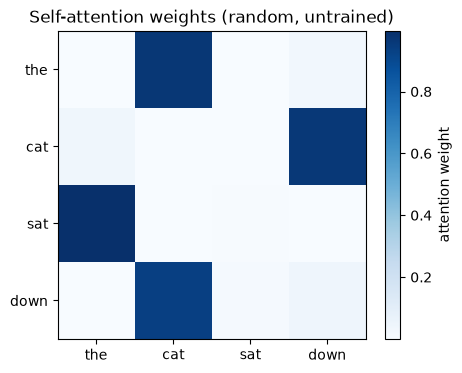

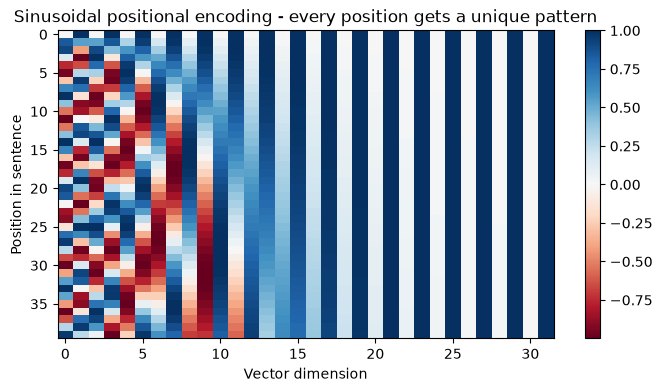

In [2]:
# ============================================================
# PART 1 - Self-attention by hand in NumPy
# ============================================================
# every word is turned into three vectors:
#   Query (Q): "what am I looking for?"
#   Key   (K): "what do I contain?"
#   Value (V): "what information do I hand over if someone attends to me?"
# attention weights = softmax( Q @ K.T / sqrt(d) )    -> how much each word attends to each other word
# output            = weights @ V                      -> a mix of the Values, weighted by attention

words = ["the", "cat", "sat", "down"]
d = 8                                           # size of each vector

embeddings = np.random.randn(len(words), d)     # one vector per word (random here, learned in a real model)

Wq = np.random.randn(d, d)
Wk = np.random.randn(d, d)
Wv = np.random.randn(d, d)

Q = embeddings @ Wq
K = embeddings @ Wk
V = embeddings @ Wv

scores = Q @ K.T / np.sqrt(d)       # dividing by sqrt(d) stops the scores growing too large

# softmax turns each row of scores into positive numbers that add up to 1
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True))
attention = exp_scores / exp_scores.sum(axis=1, keepdims=True)

output = attention @ V

print("Attention weights (row = word looking, column = word being looked at):")
print(np.round(attention, 2))
print("Each row sums to:", attention.sum(axis=1))
print("Output shape:", output.shape, "(one new vector per word)")

plt.figure(figsize=(5, 4))
plt.imshow(attention, cmap="Blues")
plt.xticks(range(len(words)), words)
plt.yticks(range(len(words)), words)
plt.colorbar(label="attention weight")
plt.title("Self-attention weights (random, untrained)")
plt.show()

# with random weights the pattern means nothing. In a trained model, a word like "it"
# learns to attend strongly to the noun it refers to, wherever that noun sits.

# ---- Positional encoding ----
# self-attention has NO sense of word order: "dog bites man" and "man bites dog" would
# look identical. So we ADD a position signal to each word vector. The original paper
# used sine/cosine waves of different frequencies.
positions = np.arange(40)[:, None]
dims = np.arange(32)[None, :]
angle_rates = 1 / np.power(10000, (2 * (dims // 2)) / 32)
angles = positions * angle_rates
pos_encoding = np.where(dims % 2 == 0, np.sin(angles), np.cos(angles))

plt.figure(figsize=(8, 4))
plt.imshow(pos_encoding, cmap="RdBu", aspect="auto")
plt.xlabel("Vector dimension")
plt.ylabel("Position in sentence")
plt.title("Sinusoidal positional encoding - every position gets a unique pattern")
plt.colorbar()
plt.show()

# (the model below uses a LEARNED position embedding instead - simpler, and common in
#  practice; BERT does the same)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 40)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_and_position_embedding  │ (None, 40, 32)            │         161,280 │ input_layer[0][0]          │
│ (TokenAndPositionEmbedding)   │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lambda (Lambda)               │ (None, 40)                │               0 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ transformer_block             │ (None, 40, 32)            │           8,544 │ token_and_position_embedd… │
│ (TransformerBlock)            │                           │                 │ lambda[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ masked_average_pooling        │ (None, 32)                │               0 │ transformer_block[0][0],   │
│ (MaskedAveragePooling)        │                           │                 │ lambda[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 32)                │               0 │ masked_average_pooling[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_2 (Dense)               │ (None, 1)                 │              33 │ dropout_3[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 169,857 (663.50 KB)

 Trainable params: 169,857 (663.50 KB)

 Non-trainable params: 0 (0.00 B)

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.93      0.95       149

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



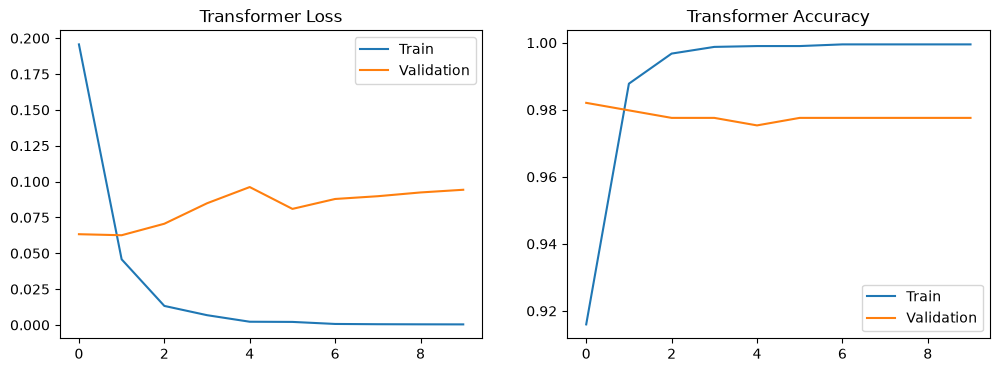

spam probability 1.00  ->  Congratulations! You have won a free prize, call now to claim
spam probability 0.00  ->  Are we still meeting for lunch tomorrow?


In [4]:
# ============================================================
# PART 2 - A Transformer encoder classifier in Keras
# ============================================================
df = pd.read_csv("../Datasets/spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"].values, df["label_num"].values,
    test_size=0.2, random_state=42, stratify=df["label_num"]
)

MAX_WORDS = 5000
SEQ_LEN = 40

vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(X_train_text)

X_train = vectorizer(X_train_text).numpy()
X_test = vectorizer(X_test_text).numpy()

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}

EMBED_DIM = 32      # size of each word vector
NUM_HEADS = 2       # attention "heads": several attention patterns learned side by side
FF_DIM = 64         # size of the feed-forward layer inside the block
# Keras has no ready-made Transformer block, so we assemble one from three small layers.

class TokenAndPositionEmbedding(layers.Layer):
    """word embedding + learned position embedding, added together"""
    def __init__(self, seq_len, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_emb = layers.Embedding(vocab_size, embed_dim)
        self.pos_emb = layers.Embedding(seq_len, embed_dim)

    def call(self, tokens):
        positions = tf.range(start=0, limit=tf.shape(tokens)[-1])
        return self.token_emb(tokens) + self.pos_emb(positions)


class TransformerBlock(layers.Layer):
    """self-attention -> add & normalise -> feed-forward -> add & normalise"""
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim // num_heads)
        self.ffn = keras.Sequential([layers.Dense(ff_dim, activation="relu"), layers.Dense(embed_dim)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, pad_mask, training=False):
        # pad_mask is True for real words and False for padding. Without it, words would
        # waste attention on the empty padding slots at the end of short messages.
        attention_mask = pad_mask[:, tf.newaxis, :]                 # shape (batch, 1, seq_len)
        attn_out = self.attention(query=x, value=x, attention_mask=attention_mask)
        x = self.norm1(x + self.drop1(attn_out, training=training))      # residual connection
        ffn_out = self.ffn(x)
        return self.norm2(x + self.drop2(ffn_out, training=training))    # residual connection


class MaskedAveragePooling(layers.Layer):
    """average the word vectors, counting only real words (not padding)"""
    def call(self, x, pad_mask):
        mask = tf.cast(pad_mask, x.dtype)[:, :, tf.newaxis]
        return tf.reduce_sum(x * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)


# ---- Assemble the model ----
tokens = layers.Input(shape=(SEQ_LEN,), dtype="int32")
pad_mask = layers.Lambda(lambda t: tf.not_equal(t, 0))(tokens)      # True where there is a real word

x = TokenAndPositionEmbedding(SEQ_LEN, MAX_WORDS, EMBED_DIM)(tokens)
x = TransformerBlock(EMBED_DIM, NUM_HEADS, FF_DIM)(x, pad_mask)
x = MaskedAveragePooling()(x, pad_mask)          # one vector summarising the message
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=tokens, outputs=outputs)
model.summary()

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=32,
    class_weight=class_weight,
    verbose=0
    )

# ---- Evaluate ----
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Transformer Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Transformer Accuracy")
axes[1].legend()
plt.show()

new_messages = np.array([
    "Congratulations! You have won a free prize, call now to claim",
    "Are we still meeting for lunch tomorrow?"
])
probs = model.predict(vectorizer(new_messages), verbose=0).ravel()
for msg, p in zip(new_messages, probs):
    print(f"spam probability {p:.2f}  ->  {msg}")

# NOTES
#   - This is ONE encoder block. Real Transformers stack 6-24 of them, and use much
#     bigger vectors. BERT-base stacks 12 blocks with 768-number vectors.
#   - A small Transformer trained from scratch on 5,000 short SMS messages will not beat
#     an LSTM by much. Transformers shine when pre-trained on huge text collections and
#     then fine-tuned - which is exactly what BERT does (script 50).